In [25]:
import json, re, textwrap
from pathlib import Path
from itertools import combinations
from collections import defaultdict, Counter

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
import networkx as nx

#PATHS FOR MY REPO
STAGE1_DIR      = Path('output/stage_1')
AGG_DATA_PATH   = STAGE1_DIR / 'aggregate_data.json'
FINDINGS_PATH   = Path('outputs/stage_2/pattern_findings.json')
METADATA_PATH   = Path('outputs/stage_2/metadata.json')
CODEBOOK_PATH   = Path('codebook.yaml')
TRANSCRIPT_DIRS = [Path('data'), Path('transcription')]

BSC_INTERVIEWS = ['I01', 'I07', 'I08', 'I09', 'I10', 'I11', 'I12']
MSC_INTERVIEWS = ['I02', 'I03', 'I04', 'I05', 'I06', 'I13', 'I14', 'I15', 'I16', 'I17']
ALL_INTERVIEWS = BSC_INTERVIEWS + MSC_INTERVIEWS
STUDENT_COUNT_OVERRIDE = {'I01': 3, 'I02': 1, 'I03': 5, 'I04': 4, 'I05': 2, 'I06': 4, 'I07': 3, 'I08': 3, 'I09': 2, 'I10': 3, 'I11': 2, 'I12': 3, 'I13': 3, 'I14': 3, 'I15': 4, 'I16': 4, 'I17': 3}     

#load json file
def load_json(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)

def walk(obj, key=None):
    """Yield (parent_key, dict) for every dict nested in obj."""
    if isinstance(obj, dict):
        yield key, obj
        for k, v in obj.items():
            yield from walk(v, k)
    elif isinstance(obj, list):
        for v in obj:
            yield from walk(v, key)

#more loading
agg_data      = load_json(AGG_DATA_PATH)
findings_data = load_json(FINDINGS_PATH)
metadata      = load_json(METADATA_PATH) if METADATA_PATH.exists() else {}
codebook      = yaml.safe_load(open(CODEBOOK_PATH, encoding='utf-8'))
findings      = findings_data['findings']
code_matrix   = agg_data['code_interview_matrix']            # {code: {interview: n_quotes}}
interview_jsons = {iid: [load_json(p) for p in sorted((STAGE1_DIR / iid).rglob('*.json'))]
                   for iid in ALL_INTERVIEWS if (STAGE1_DIR / iid).exists()}

#codebook disect
code_names, theme_names = {}, {}
for key, node in walk(codebook):
    if 'codes' not in node:
        continue
    theme_name = node.get('name') or node.get('label') or ''
    codes = node['codes']
    items = codes.items() if isinstance(codes, dict) else [(None, c) for c in codes]
    for k, v in items:
        if isinstance(v, dict):
            cid, cname = v.get('id') or v.get('code') or k, v.get('name') or v.get('label') or ''
        else:
            cid, cname = (k, v) if k is not None else (v, '')
        cid = str(cid).strip()
        if re.fullmatch(r'[A-Za-z]', cid):                  # "a" nested under theme "1"
            cid = f"{re.search(r'\d+', str(node.get('id', key))).group()}.{cid}"
        if re.fullmatch(r'\d+\.[A-Za-z0-9]+', cid):
            code_names[cid] = str(cname).strip()
            theme_names.setdefault(cid.split('.')[0], theme_name)

for c in code_matrix:                                       # codes in data but not in codebook
    code_names.setdefault(c, '')
    theme_names.setdefault(c.split('.')[0], '')

CODES  = sorted(code_names)
THEMES = sorted(theme_names, key=int)
code_to_theme = {c: c.split('.')[0] for c in CODES}

def theme_label(t):
    return f'Theme {t}: {theme_names[t]}' if theme_names[t] else f'Theme {t}'

SHOW_CODE_IDS = False      # True → "1.a – Name", False → "Name"

def code_label(c, width=None):
    name = code_names[c]
    s = f'{c} – {name}' if (SHOW_CODE_IDS and name) else (name or c)
    return textwrap.fill(s, width) if width else s

#COLOUR SCHEME
THEME_COLOR   = {'1': '#3B78B5', '2': '#3FA07A', '3': '#8E63B5'}   # blue, green, violet
FINDING_COLOR = '#6B7785'

def shade(hex_color, f):
    """f < 0 darkens, f > 0 lightens."""
    c = np.array(mcolors.to_rgb(hex_color))
    c = c * (1 + f) if f < 0 else c * (1 - f) + f
    return mcolors.to_hex(np.clip(c, 0, 1))

CODE_COLOR = {}
for t in THEMES:
    tcodes = [c for c in CODES if code_to_theme[c] == t]
    fracs = [0.0] if len(tcodes) == 1 else np.linspace(-0.20, 0.45, len(tcodes))
    CODE_COLOR.update({c: shade(THEME_COLOR[t], f) for c, f in zip(tcodes, fracs)})

def text_on(color):
    r, g, b = mcolors.to_rgb(color)
    return '#1A1A1A' if 0.299 * r + 0.587 * g + 0.114 * b > 0.6 else 'white'

def theme_legend_handles():
    return [mpatches.Patch(color=THEME_COLOR[t], label=theme_label(t)) for t in THEMES]

#student counts
NUM_WORDS = {w: i for i, w in enumerate('zero one two three four five six seven eight nine ten'.split())}
STUDENT_RE = re.compile(r'(\d+|' + '|'.join(NUM_WORDS) + r')\s+(?:students?|participants?)'
                        r'|(?:students?|participants?)\s*[:=]\s*(\d+)', re.I)

def students_from_json(iid):
    for src in [metadata, agg_data] + interview_jsons.get(iid, []):
        for key, node in walk(src):
            if key == iid or iid in (node.get('interview_id'), node.get('id')) or src in interview_jsons.get(iid, []):
                for k, v in node.items():
                    if re.search(r'student|participant', str(k), re.I) and isinstance(v, (int, list)) and not isinstance(v, bool):
                        return v if isinstance(v, int) else len(v)
    return None

def students_from_transcript(iid):
    for d in TRANSCRIPT_DIRS:
        for p in sorted(d.rglob(f'{iid}*')) if d.exists() else []:
            if p.is_file() and p.suffix.lower() in ('.txt', '.md'):
                m = STUDENT_RE.search(p.read_text(encoding='utf-8', errors='ignore')[:3000])
                if m:
                    n = m.group(1) or m.group(2)
                    return int(n) if n.isdigit() else NUM_WORDS[n.lower()]
    return None

student_counts = {iid: STUDENT_COUNT_OVERRIDE.get(iid) or students_from_json(iid) or students_from_transcript(iid)
                  for iid in ALL_INTERVIEWS}

def n_students(ids):
    vals = [student_counts[i] for i in ids]
    return None if None in vals else sum(vals)

N_STUDENTS = {'BSc': n_students(BSC_INTERVIEWS), 'MSc': n_students(MSC_INTERVIEWS),
              'Total': n_students(ALL_INTERVIEWS)}

# Quotes per code + quote → codes map
CODE_TOTALS  = {c: int(sum(code_matrix.get(c, {}).values())) for c in CODES}
TOTAL_QUOTES = sum(CODE_TOTALS.values())

quote_codes = defaultdict(set)
for src in [agg_data] + [j for js in interview_jsons.values() for j in js]:
    for _, node in walk(src):
        qids = [node.get('quote_id')] + (node.get('quote_ids') or [])
        codes = node.get('codes') or node.get('code') or []
        codes = [codes] if isinstance(codes, str) else codes
        for q in qids:
            if isinstance(q, str):
                quote_codes[q] |= {str(c) for c in codes if str(c) in code_names}

finding_qids = {q for f in findings for q in f['quote_ids']}
USE_QUOTE_LEVEL = sum(bool(quote_codes.get(q)) for q in finding_qids) >= 0.8 * len(finding_qids)

#PRINT TO CHECK
print(f'Total interviews: {len(ALL_INTERVIEWS)}')
print(f'BSc ({len(BSC_INTERVIEWS)}): {", ".join(BSC_INTERVIEWS)}')
print(f'MSc ({len(MSC_INTERVIEWS)}): {", ".join(MSC_INTERVIEWS)}')
print('\nStudents per interview:', {i: student_counts[i] for i in ALL_INTERVIEWS})
print(f'BSc students: {N_STUDENTS["BSc"]} | MSc students: {N_STUDENTS["MSc"]} | Total: {N_STUDENTS["Total"]}')
if None in student_counts.values():
    print('⚠ Some student counts not found → fill STUDENT_COUNT_OVERRIDE')
print(f'\nTotal coded quotes: {TOTAL_QUOTES}')
print(f'Findings: {len(findings)}', dict(Counter(f["finding_type"] for f in findings)))
print(f'Quote→code mapping: {"quote-level" if USE_QUOTE_LEVEL else "FALLBACK (codes_involved)"}')
print('\nColour scheme:')
for t in THEMES:
    print(f'  {THEME_COLOR[t]}  {theme_label(t)}')
    for c in CODES:
        if code_to_theme[c] == t:
            print(f'      {CODE_COLOR[c]}  {code_label(c)}  ({CODE_TOTALS[c]} quotes)')

Total interviews: 17
BSc (7): I01, I07, I08, I09, I10, I11, I12
MSc (10): I02, I03, I04, I05, I06, I13, I14, I15, I16, I17

Students per interview: {'I01': 3, 'I07': 3, 'I08': 3, 'I09': 2, 'I10': 3, 'I11': 2, 'I12': 3, 'I02': 1, 'I03': 5, 'I04': 4, 'I05': 2, 'I06': 4, 'I13': 3, 'I14': 3, 'I15': 4, 'I16': 4, 'I17': 3}
BSc students: 19 | MSc students: 33 | Total: 52

Total coded quotes: 503
Findings: 13 {'alignment': 2, 'tension': 2, 'contradiction': 2, 'subtlety': 1, 'emerging_pattern': 2, 'irrelevant_pattern': 4}
Quote→code mapping: quote-level

Colour scheme:
  #3B78B5  Theme 1: Students' self-efficacy
      #3b78b5  Problem-solving experience  (132 quotes)
  #3FA07A  Theme 2: Student Identity
      #328062  Quantum scientist identity  (14 quotes)
      #57ac8b  Theorist identity  (9 quotes)
      #95cbb6  Experimentalist / practical identity  (23 quotes)
  #8E63B5  Theme 3: Apparent takeaway of students
      #724f91  Laboratory equipment  (98 quotes)
      #9066b6  Positive learning

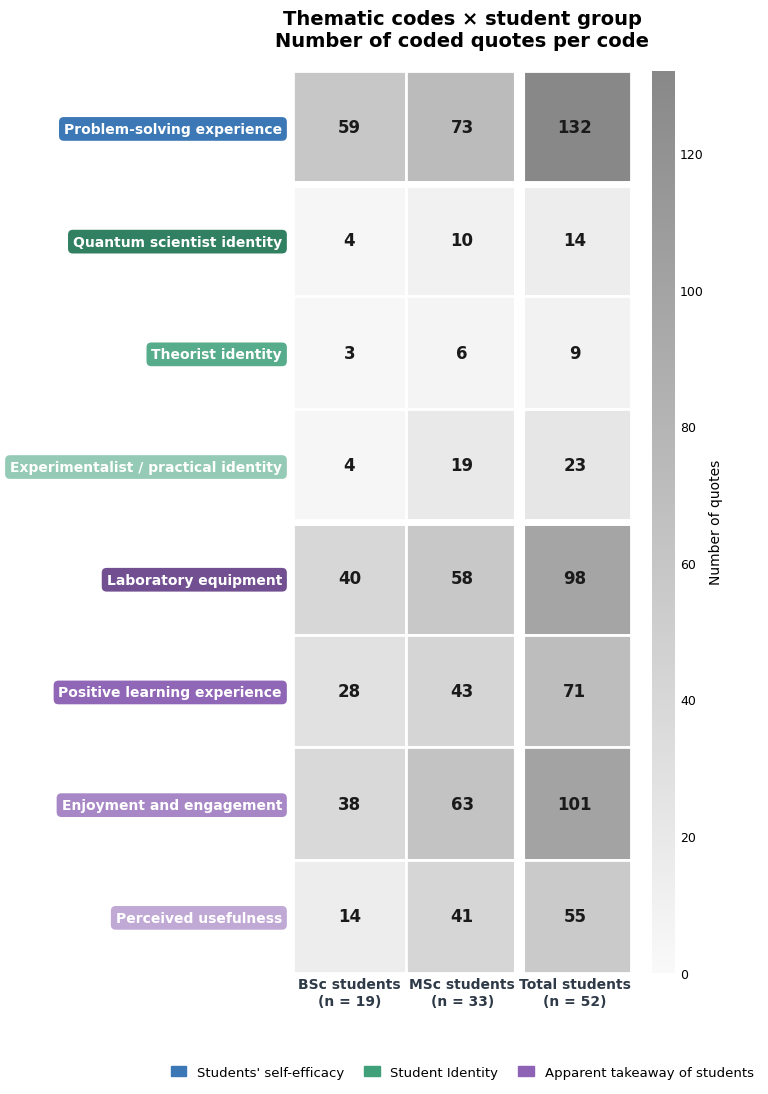

                                      BSc  MSc  Total
Problem-solving experience             59   73    132
Quantum scientist identity              4   10     14
Theorist identity                       3    6      9
Experimentalist / practical identity    4   19     23
Laboratory equipment                   40   58     98
Positive learning experience           28   43     71
Enjoyment and engagement               38   63    101
Perceived usefulness                   14   41     55

Column totals: {'BSc': 190, 'MSc': 313, 'Total': 503}  (expected total 503)


In [ ]:
df_codes = (pd.DataFrame(code_matrix).T
              .reindex(index=CODES, columns=ALL_INTERVIEWS).fillna(0).astype(int))
summary = pd.DataFrame({'BSc':   df_codes[BSC_INTERVIEWS].sum(axis=1),
                        'MSc':   df_codes[MSC_INTERVIEWS].sum(axis=1),
                        'Total': df_codes.sum(axis=1)})

col_labels = [f'BSc students\n(n = {N_STUDENTS["BSc"]})',
              f'MSc students\n(n = {N_STUDENTS["MSc"]})',
              f'Total students\n(n = {N_STUDENTS["Total"]})']

# Neutral light grey scale (pure greys, no tint)
GREY_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'quotes', [plt.cm.Greys(0.05), plt.cm.Greys(0.55)])
NORM = mcolors.Normalize(vmin=0, vmax=summary.values.max())

fig, ax = plt.subplots(figsize=(10, 11))
for i, code in enumerate(CODES):
    for j, col in enumerate(summary.columns):
        val = int(summary.at[code, col])
        ax.add_patch(mpatches.Rectangle((j, i), 1, 1, facecolor=GREY_CMAP(NORM(val)),
                                        edgecolor='white', lw=2))
        ax.text(j + 0.5, i + 0.5, val, ha='center', va='center',
                fontsize=12, fontweight='bold', color='#1A1A1A')

ax.axvline(2, color='white', lw=8)                              # gap before Total
for i in range(1, len(CODES)):                                  # gap between themes
    if code_to_theme[CODES[i]] != code_to_theme[CODES[i - 1]]:
        ax.axhline(i, color='white', lw=5)

ax.set_xlim(0, 3); ax.set_ylim(len(CODES), 0)
ax.set_aspect('equal')                                          # square cells
ax.set_xticks(np.arange(3) + 0.5); ax.set_xticklabels(col_labels, fontweight='bold', color='#2F3A48')
ax.set_yticks(np.arange(len(CODES)) + 0.5); ax.set_yticklabels([code_label(c, 38) for c in CODES])
for lbl, code in zip(ax.get_yticklabels(), CODES):
    lbl.set_fontweight('bold'); lbl.set_color('white')
    lbl.set_bbox(dict(boxstyle='round,pad=0.35', fc=CODE_COLOR[code], ec='none'))
ax.tick_params(length=0); ax.tick_params(axis='y', pad=8)
for s in ax.spines.values():
    s.set_visible(False)

cax = ax.inset_axes([1.06, 0.0, 0.07, 1.0])                     # axes fraction → full matrix height
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=GREY_CMAP, norm=NORM), cax=cax, orientation='vertical')
cb.set_label('Number of quotes', fontsize=10)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=9, length=0)

theme_handles = [mpatches.Patch(color=THEME_COLOR[t], label=theme_names[t] or f'Theme {t}') for t in THEMES]
ax.legend(handles=theme_handles, loc='upper center', bbox_to_anchor=(0.5, -0.09),
          ncol=len(THEMES), frameon=False, fontsize=9.5, handlelength=1.2, columnspacing=1.5)

ax.set_title('Thematic codes × student group\nNumber of coded quotes per code',
             fontsize=14, fontweight='bold', pad=18)
plt.tight_layout()
plt.show()

summary.index = [code_label(c) for c in CODES]
print(summary)
print(f'\nColumn totals: {summary.sum().to_dict()}  (expected total {TOTAL_QUOTES})')

Cited quotes: 96 citations · 87 distinct quotes


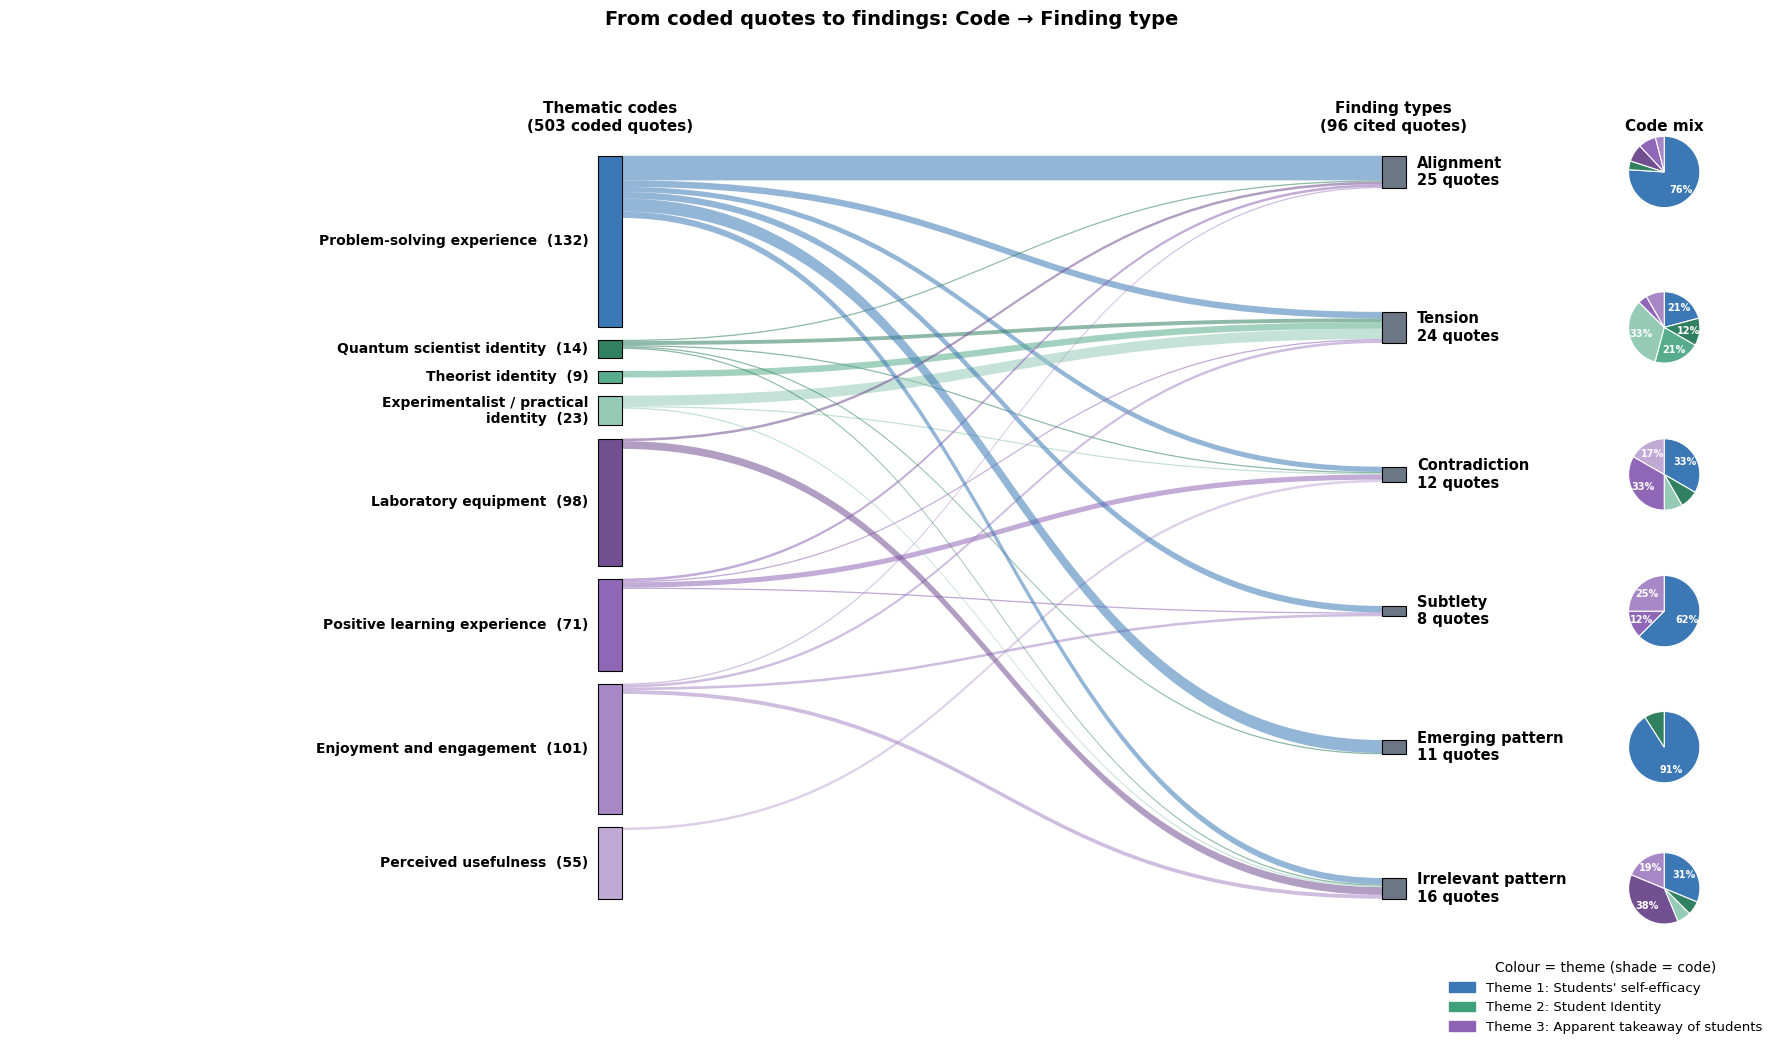

       total_quotes  alignment  tension  contradiction  subtlety  \
1.a             132         19        5              4         5   
2.a              14          1        3              1         0   
2.b               9          0        5              0         0   
2.c              23          0        8              1         0   
3.a              98          2        0              0         0   
3.b              71          2        1              4         1   
3.c             101          1        2              0         2   
3.d              55          0        0              2         0   
TOTAL           503         25       24             12         8   

       emerging_pattern  irrelevant_pattern  
1.a                  10                   5  
2.a                   1                   1  
2.b                   0                   0  
2.c                   0                   1  
3.a                   0                   6  
3.b                   0                   0

In [27]:
FINDINGS_MD = Path('outputs/stage_2/pattern_findings.md')
CITE_RE = re.compile(r'^- \[(I\d+-Q\d+)\s*\|\s*I\d+\s*\|\s*(\d+\.[A-Za-z0-9]+)\]')

citations, ftype = [], None                     # list of (finding_type, quote_id, code)
for line in FINDINGS_MD.read_text(encoding='utf-8').splitlines():
    if line.startswith('## '):
        ftype = line[3:].strip().lower().replace(' ', '_')
    elif ftype and (m := CITE_RE.match(line.strip())):
        citations.append((ftype, m.group(1), m.group(2)))

FINDING_ORDER = ['alignment', 'tension', 'contradiction', 'subtlety', 'emerging_pattern', 'irrelevant_pattern']
found = {t for t, _, _ in citations}
FTYPES = [t for t in FINDING_ORDER if t in found] + sorted(found - set(FINDING_ORDER))
flows = Counter((c, t) for t, _, c in citations)          # (code, finding_type) -> n citations

unknown = sorted({c for _, _, c in citations} - set(CODES))
if unknown:
    print(f'⚠ Codes in findings but not in codebook: {unknown}')
print(f'Cited quotes: {len(citations)} citations · {len({q for _, q, _ in citations})} distinct quotes')

# ---- Node sizes ----
L = {c: max(CODE_TOTALS[c], sum(v for (s, _), v in flows.items() if s == c)) for c in CODES}
R = {t: sum(v for (_, s), v in flows.items() if s == t) for t in FTYPES}

gapL  = 0.02 * sum(L.values())
scale = max(sum(L.values()) + gapL * (len(L) - 1), 1.4 * sum(R.values()))
gapR  = (scale - sum(R.values())) / max(len(R) - 1, 1)          # findings spread over full height
NW = 0.03

def place(vals, gap, x):
    h = sum(vals.values()) + gap * (len(vals) - 1)
    pos, y = {}, 1 - (scale - h) / 2 / scale
    for n, v in vals.items():
        pos[n] = (x, y - v / scale, y)
        y -= (v + gap) / scale
    return pos
posL, posR = place(L, gapL, 0.0), place(R, gapR, 1.0)

out_off, in_off = {}, {}
for c in CODES:
    y = posL[c][2]
    for t in FTYPES:
        if flows.get((c, t)):
            out_off[(c, t)] = y; y -= flows[(c, t)] / scale
for t in FTYPES:
    y = posR[t][2]
    for c in CODES:
        if flows.get((c, t)):
            in_off[(c, t)] = y; y -= flows[(c, t)] / scale


fig, ax = plt.subplots(figsize=(18, 11))
for (c, t), v in flows.items():
    if c not in CODE_COLOR:
        continue
    h, y0, y1, xm = v / scale, out_off[(c, t)], in_off[(c, t)], (NW + 1) / 2
    verts = [(NW, y0), (xm, y0), (xm, y1), (1, y1), (1, y1 - h), (xm, y1 - h), (xm, y0 - h), (NW, y0 - h), (NW, y0)]
    codes = [MplPath.MOVETO] + [MplPath.CURVE4] * 3 + [MplPath.LINETO] + [MplPath.CURVE4] * 3 + [MplPath.CLOSEPOLY]
    ax.add_patch(mpatches.PathPatch(MplPath(verts, codes), fc=CODE_COLOR[c], ec='none', alpha=0.55))


for c, (x, yb, yt) in posL.items():
    ax.add_patch(mpatches.Rectangle((x, yb), NW, yt - yb, fc=CODE_COLOR[c], ec='black', lw=0.8, zorder=5))
    ax.text(x - 0.012, (yb + yt) / 2, f'{code_label(c, 34)}  ({CODE_TOTALS[c]})',
            ha='right', va='center', fontsize=10, fontweight='bold')

PIE = 0.12
for t, (x, yb, yt) in posR.items():
    yc = (yb + yt) / 2
    ax.add_patch(mpatches.Rectangle((x, yb), NW, yt - yb, fc=FINDING_COLOR, ec='black', lw=0.8, zorder=5))
    ax.text(x + NW + 0.015, yc, f'{t.replace("_", " ").capitalize()}\n{R[t]} quotes',
            ha='left', va='center', fontsize=10.5, fontweight='bold')

    mix = [(c, flows[(c, t)]) for c in CODES if flows.get((c, t))]
    pax = ax.inset_axes([1.30, yc - PIE / 2, PIE, PIE], transform=ax.transData)
    pax.pie([v for _, v in mix], colors=[CODE_COLOR[c] for c, _ in mix], startangle=90, counterclock=False,
            wedgeprops=dict(edgecolor='white', linewidth=0.8),
            autopct=lambda p: f'{p:.0f}%' if p >= 10 else '', pctdistance=0.68,
            textprops=dict(fontsize=7, fontweight='bold', color='white'))
    pax.set_aspect('equal')

# ---- Headers, legend, notes ----
ax.text(NW / 2, 1.03, f'Thematic codes\n({TOTAL_QUOTES} coded quotes)',
        ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.text(1 + NW / 2, 1.03, f'Finding types\n({len(citations)} cited quotes)',
        ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.text(1.30 + PIE / 2, 1.03, 'Code mix', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xlim(-0.75, 1.5); ax.set_ylim(-0.02, 1.12); ax.axis('off')
ax.set_title('From coded quotes to findings: Code → Finding type',
             fontsize=14, fontweight='bold', pad=30)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.13)
fig.legend(handles=theme_legend_handles(), loc='lower right', bbox_to_anchor=(0.99, 0.01),
           fontsize=9.5, title='Colour = theme (shade = code)', frameon=False)
plt.show()

flow_df = pd.Series(flows).unstack(fill_value=0).reindex(index=CODES, columns=FTYPES, fill_value=0)
flow_df.insert(0, 'total_quotes', [CODE_TOTALS[c] for c in CODES])
flow_df.loc['TOTAL'] = flow_df.sum()
print(flow_df)